# Day 1 — FreshRetailNet-50K Data Exploration

**Project goal:** estimate demand hidden by stockouts, forecast demand, then evaluate inventory-ordering decisions.

This notebook documents the first dataset checks. Run cells from top to bottom. Read each explanation before running the next cell.

**Important principles**
- Recorded sales may be lower than demand during stockouts.
- Do not treat recovered/imputed demand as ground truth.
- Do not delete duplicates or change sales values before investigating them.
- These first checks use the official Hugging Face dataset and begin with a 20,000-row sample for speed.


## 1. Set up and load the dataset

We use the same dataset loader as the baseline repository. The first load downloads the dataset if it is not already cached. It may take a little while.

In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np
from collections import Counter

DATASET_NAME = "Dingdong-Inc/FreshRetailNet-50K"

dataset = load_dataset(DATASET_NAME)

print(dataset)
print("\nSplits:", list(dataset.keys()))


d:\FreshRetailNet-Project\frn-50k-baseline\py3.8_frn\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 4500000
    })
    eval: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 350000
    })
})

Splits: ['train', 'eval']


### What this tells us

- **Splits** are predefined portions of the dataset, such as `train` and `eval`.
- A row represents a store-product record for a date; hourly information is stored inside list-valued columns.
- We will inspect the actual schema rather than guessing field names.


In [2]:
train = dataset["train"]
eval_data = dataset["eval"]

print("Training rows:", len(train))
print("Evaluation rows:", len(eval_data))
print("Columns:", train.column_names)
print("\nFeature types:")
print(train.features)


Training rows: 4500000
Evaluation rows: 350000
Columns: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']

Feature types:
{'city_id': Value(dtype='int64', id=None), 'store_id': Value(dtype='int64', id=None), 'management_group_id': Value(dtype='int64', id=None), 'first_category_id': Value(dtype='int64', id=None), 'second_category_id': Value(dtype='int64', id=None), 'third_category_id': Value(dtype='int64', id=None), 'product_id': Value(dtype='int64', id=None), 'dt': Value(dtype='string', id=None), 'sale_amount': Value(dtype='float64', id=None), 'hours_sale': [Value(dtype='float64', id=None)], 'stock_hour6_22_cnt': Value(dtype='int32', id=None), 'hours_stock_status': [Value(dtype='int64', id=None)], 'discount': Value(dtype='float6

## 2. Inspect one record

`hours_sale` and `hours_stock_status` are list-valued columns. We should verify their lengths and meanings before using them in a model.

In [3]:
first_row = train[0]
for column, value in first_row.items():
    print(f"{column}: {value}")


city_id: 0
store_id: 0
management_group_id: 0
first_category_id: 5
second_category_id: 6
third_category_id: 65
product_id: 38
dt: 2024-03-28
sale_amount: 0.1
hours_sale: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
stock_hour6_22_cnt: 0
hours_stock_status: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
discount: 1.0
holiday_flag: 0
activity_flag: 0
precpt: 1.6999
avg_temperature: 15.48
avg_humidity: 73.54
avg_wind_level: 1.97


## 3. Create a sample for initial quality checks

We inspect the first 20,000 training records to keep the initial checks manageable. **These sample results are not automatically full-dataset results.** Later, we can run targeted checks across the full dataset if needed.

In [4]:
SAMPLE_SIZE = min(20_000, len(train))
df = train.select(range(SAMPLE_SIZE)).to_pandas()

print(f"Sample rows: {len(df):,}")
print(f"Sample columns: {len(df.columns)}")
display(df.head())


Sample rows: 20,000
Sample columns: 19


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25


## 4. Column guide

This table summarizes likely roles based on the column names and observed schema. Items marked **verify** should be checked against the baseline code or dataset documentation before we rely on them.

In [5]:
column_guide = pd.DataFrame([
    ("city_id", "City identifier", "Identifier"),
    ("store_id", "Store identifier", "Series key"),
    ("management_group_id", "Management group identifier", "Identifier"),
    ("first_category_id", "Product category level 1", "Identifier"),
    ("second_category_id", "Product category level 2", "Identifier"),
    ("third_category_id", "Product category level 3", "Identifier"),
    ("product_id", "Product identifier", "Series key"),
    ("dt", "Date stored as a string", "Time"),
    ("sale_amount", "Daily recorded sales amount", "Target-related; verify units"),
    ("hours_sale", "List of hourly sales values", "Hourly target-related"),
    ("stock_hour6_22_cnt", "Stock-related count; exact definition needs verification", "Stock-related"),
    ("hours_stock_status", "List of hourly stock-status values; code meanings need verification", "Stock annotation"),
    ("discount", "Discount feature", "Covariate"),
    ("holiday_flag", "Holiday indicator", "Covariate"),
    ("activity_flag", "Activity indicator", "Covariate"),
    ("precpt", "Precipitation feature", "Covariate"),
    ("avg_temperature", "Average temperature", "Covariate"),
    ("avg_humidity", "Average humidity", "Covariate"),
    ("avg_wind_level", "Average wind level", "Covariate"),
], columns=["column", "working_interpretation", "role"])
display(column_guide)


,column,working_interpretation,role
0,city_id,City identifier,Identifier
1,store_id,Store identifier,Series key
2,management_group_id,Management group identifier,Identifier
3,first_category_id,Product category level 1,Identifier
4,second_category_id,Product category level 2,Identifier
5,third_category_id,Product category level 3,Identifier
6,product_id,Product identifier,Series key
7,dt,Date stored as a string,Time
8,sale_amount,Daily recorded sales amount,Target-related; verify units
9,hours_sale,List of hourly sales values,Hourly target-related


## 5. Missing-value check

This checks missing values in the sample only. An empty list is different from a missing value, so list lengths are checked separately below.

In [6]:
missing = df.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(3)
})
display(missing_summary)


,missing_count,missing_percent
city_id,0,0.0
stock_hour6_22_cnt,0,0.0
avg_humidity,0,0.0
avg_temperature,0,0.0
precpt,0,0.0
activity_flag,0,0.0
holiday_flag,0,0.0
discount,0,0.0
hours_stock_status,0,0.0
hours_sale,0,0.0


## 6. Duplicate store-product-date keys

A duplicate key means the same `(store_id, product_id, dt)` appears more than once in the sample. We count these rows but **do not remove them** until we understand why they exist.

In [7]:
key_columns = ["store_id", "product_id", "dt"]
duplicate_mask = df.duplicated(subset=key_columns, keep=False)

print("Rows participating in duplicate keys:", int(duplicate_mask.sum()))
print("Duplicate key groups:", int(df.loc[duplicate_mask, key_columns].drop_duplicates().shape[0]))

if duplicate_mask.any():
    display(df.loc[duplicate_mask, key_columns + ["sale_amount"]].head(20))
else:
    print("No duplicate keys found in this sample.")


Rows participating in duplicate keys: 0
Duplicate key groups: 0
No duplicate keys found in this sample.


## 7. Daily sales sanity check

Negative values can indicate a data issue or a special business rule. We report them rather than changing them. The units of `sale_amount` should be verified before interpreting its magnitude.

In [8]:
print("sale_amount summary:")
display(df["sale_amount"].describe().to_frame())

print("Negative sale_amount rows:", int((df["sale_amount"] < 0).sum()))
print("Zero sale_amount rows:", int((df["sale_amount"] == 0).sum()))
print("Missing sale_amount rows:", int(df["sale_amount"].isna().sum()))


sale_amount summary:


,sale_amount
count,20000.000000
mean,1.104425
std,1.353156
min,0.000000
25%,0.400000
50%,0.700000
75%,1.200000
max,21.300000


Negative sale_amount rows: 0
Zero sale_amount rows: 600
Missing sale_amount rows: 0


## 8. Hourly-list lengths

The dataset schema shows list-valued hourly fields. We check whether their lengths are consistent and whether they have the expected 24 values. We do not silently repair rows with unexpected lengths.

In [9]:
for column in ["hours_sale", "hours_stock_status"]:
    lengths = df[column].dropna().map(len)
    print(f"\n{column} list lengths:")
    display(lengths.value_counts().sort_index().rename_axis("list_length").to_frame("row_count"))
    print("Missing list rows:", int(df[column].isna().sum()))



hours_sale list lengths:


,row_count
list_length,
24,20000


Missing list rows: 0

hours_stock_status list lengths:


,row_count
list_length,
24,20000


Missing list rows: 0


## 9. Inspect stock-status values

This reports the distinct status values observed inside the sample's hourly lists. **Do not assume which number means in-stock or stockout yet.** We will verify the coding from the dataset documentation and baseline source.

In [10]:
status_values = sorted({
    value
    for values in df["hours_stock_status"].dropna()
    for value in values
})
print("Distinct hourly stock-status values in sample:", status_values)

print("\nFirst five status lists:")
for row_number, values in enumerate(df["hours_stock_status"].head(5).tolist()):
    print(row_number, values)


Distinct hourly stock-status values in sample: [0, 1]

First five status lists:
0 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
1 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1]
2 [1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
3 [0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1]
4 [1 1 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1]


## 10. Inspect time coverage and series keys

`dt` is a string in the dataset schema. We parse a separate copy as dates to inspect coverage; this does not alter the original dataset.

In [11]:
dates = pd.to_datetime(df["dt"], errors="coerce")
print("Unparseable dates in sample:", int(dates.isna().sum()))
print("Earliest sample date:", dates.min())
print("Latest sample date:", dates.max())
print("Distinct stores in sample:", df["store_id"].nunique())
print("Distinct products in sample:", df["product_id"].nunique())
print("Distinct store-product pairs in sample:", df[["store_id", "product_id"]].drop_duplicates().shape[0])


Unparseable dates in sample: 0
Earliest sample date: 2024-03-28 00:00:00
Latest sample date: 2024-06-25 00:00:00
Distinct stores in sample: 3
Distinct products in sample: 152
Distinct store-product pairs in sample: 223


## 11. Read the baseline's SSA input logic

Run this cell from the repository root. It prints the relevant source file so we can confirm how the baseline loads data, selects targets, and evaluates forecasts. It does not execute the forecasting model.

In [12]:
from pathlib import Path

ssa_path = Path("demand_forecasting/SSA/ssa_forecasting.py")
if ssa_path.exists():
    print(ssa_path.read_text(encoding="utf-8"))
else:
    print(f"File not found from current working directory: {Path.cwd()}")
    print("Change the notebook working directory to the repository root, then rerun.")


import pandas as pd
import numpy as np
from datasets import load_dataset
import argparse

def ssa_predict(demand_df, target_col='sale_amount'):
    dataset = load_dataset("Dingdong-Inc/FreshRetailNet-50K")
    eval_df = dataset['eval'].to_pandas()
    all_data = pd.concat([demand_df, eval_df], axis=0)
    all_data = all_data.sort_values(by=['store_id', 'product_id', 'dt'])
    # calendar feature
    all_data['time_idx'] = (pd.to_datetime(all_data['dt']) - pd.to_datetime(all_data['dt']).min()).dt.days
    all_data['dow'] = pd.to_datetime(all_data['dt']).dt.dayofweek
    all_data.loc[all_data['dt'].isin(['2024-05-02','2024-05-03','2024-05-04']), 'holiday_flag']=0
    all_data.loc[all_data['holiday_flag']==1, 'dow'] = 5
    all_data.loc[(all_data['holiday_flag']==0)&(all_data['dow'].isin([5,6])), 'dow'] = 0
    # precipitation feature
    all_data['is_precpt'] = (all_data['precpt']>3.5).astype(int)
    # continuouse and catigorical variables
    x_cont = all_data[['time_idx', 'discount', 

## 12. First baseline forecast

We will forecast daily recorded sales for one store-product series.

- Method: 7-day seasonal naive forecast
- Input: sale_amount
- Split: chronological; the final 20% of dates are reserved for testing
- Metric: Mean Absolute Error (MAE)
- Limitation: Recorded sales may be censored during stockouts.

## Step 13 — Add the forecasting code

In [13]:

import pandas as pd
import numpy as np

# Use the dataset already loaded in the notebook.
# Select the most frequently observed store-product pair in the sample.
pair_counts = (
    df.groupby(["store_id", "product_id"])
      .size()
      .sort_values(ascending=False)
)

store_id, product_id = pair_counts.index[0]

series = df[
    (df["store_id"] == store_id) &
    (df["product_id"] == product_id)
][["dt", "sale_amount"]].copy()

series["dt"] = pd.to_datetime(series["dt"])
series = series.sort_values("dt").reset_index(drop=True)

print("Selected store:", store_id)
print("Selected product:", product_id)
print("Observations:", len(series))
print("Date range:", series["dt"].min(), "to", series["dt"].max())

display(series.head())


Selected store: 0
Selected product: 4
Observations: 90
Date range: 2024-03-28 00:00:00 to 2024-06-25 00:00:00


,dt,sale_amount
0,2024-03-28,0.5
1,2024-03-29,1.3
2,2024-03-30,5.3
3,2024-03-31,4.2
4,2024-04-01,0.7


## Step 14 — Evaluate the forecast


In [14]:

# Require enough observations for a meaningful weekly comparison.
if len(series) < 14:
    print("Not enough observations for this experiment. Select a pair with more dates.")
else:
    split = int(len(series) * 0.8)

    train_series = series.iloc[:split].copy()
    test_series = series.iloc[split:].copy()

    # Forecast each test date using sales from seven observations earlier.
    history = series["sale_amount"].to_numpy()
    predictions = []

    for i in range(split, len(series)):
        predictions.append(history[i - 7])

    actual = test_series["sale_amount"].to_numpy()
    predictions = np.asarray(predictions)

    mae = np.mean(np.abs(actual - predictions))
    bias = np.mean(predictions - actual)

    results = pd.DataFrame({
        "dt": test_series["dt"].to_numpy(),
        "actual_sales": actual,
        "predicted_sales": predictions
    })

    print("Training observations:", len(train_series))
    print("Testing observations:", len(test_series))
    print("Test period:", test_series["dt"].min(), "to", test_series["dt"].max())
    print("MAE:", round(float(mae), 4))
    print("Forecast bias (prediction - actual):", round(float(bias), 4))

    display(results.head(15))


Training observations: 72
Testing observations: 18
Test period: 2024-06-08 00:00:00 to 2024-06-25 00:00:00
MAE: 1.2833
Forecast bias (prediction - actual): 0.7833


,dt,actual_sales,predicted_sales
0,2024-06-08,1.6,5.9
1,2024-06-09,3.1,6.5
2,2024-06-10,3.2,1.5
3,2024-06-11,0.8,1.4
4,2024-06-12,0.3,1.2
5,2024-06-13,0.5,0.0
6,2024-06-14,0.9,3.1
7,2024-06-15,3.1,1.6
8,2024-06-16,2.4,3.1
9,2024-06-17,0.1,3.2


## Step 15 — Verify that the weekly comparison is valid

In [15]:

# Check whether the selected series has one observation per calendar day.
date_gaps = series["dt"].diff().dropna()

print("Number of date intervals:", len(date_gaps))
print("Intervals of exactly 1 day:", int((date_gaps == pd.Timedelta(days=1)).sum()))
print("Intervals longer than 1 day:", int((date_gaps > pd.Timedelta(days=1)).sum()))
print("Duplicate dates:", int(series["dt"].duplicated().sum()))

expected_dates = pd.date_range(
    start=series["dt"].min(),
    end=series["dt"].max(),
    freq="D"
)

print("Expected calendar days:", len(expected_dates))
print("Observed unique dates:", series["dt"].nunique())
print("Complete daily series:", series["dt"].nunique() == len(expected_dates))


Number of date intervals: 89
Intervals of exactly 1 day: 89
Intervals longer than 1 day: 0
Duplicate dates: 0
Expected calendar days: 90
Observed unique dates: 90
Complete daily series: True


## Step 16 — Visualize actual versus predicted sales

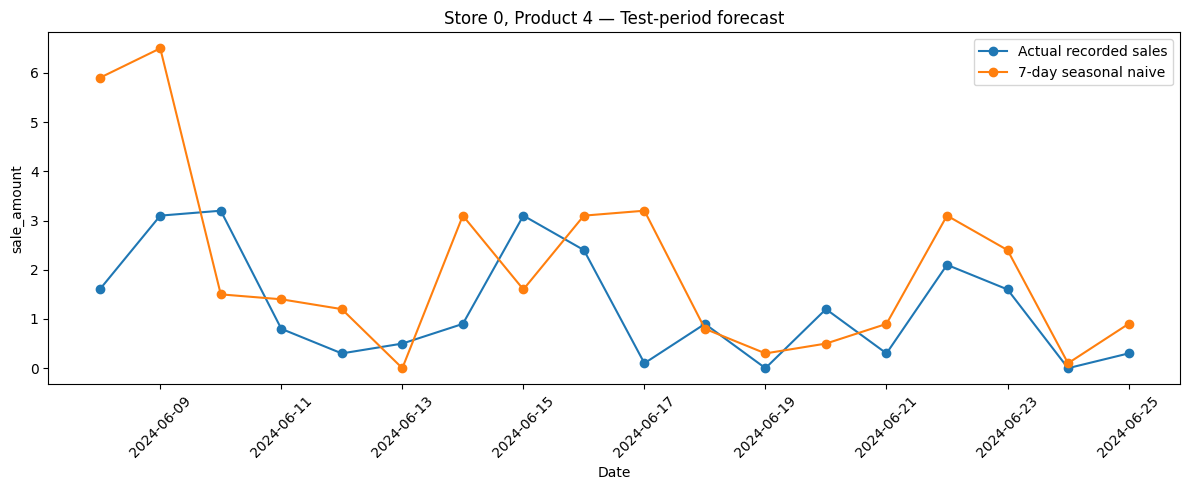

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(results["dt"], results["actual_sales"], marker="o", label="Actual recorded sales")
plt.plot(results["dt"], results["predicted_sales"], marker="o", label="7-day seasonal naive")
plt.title("Store 0, Product 4 — Test-period forecast")
plt.xlabel("Date")
plt.ylabel("sale_amount")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 17. First baseline — Results and interpretation

**Series:** Store 0, Product 4

**Method:** 7-day seasonal naive forecast

**Target:** `sale_amount` (recorded daily sales)

**Training period:** 72 observations

**Test period:** 2024-06-08 to 2024-06-25 (18 observations)

**Results:**
- MAE: 1.2833
- Forecast bias (prediction - actual): +0.7833

**Data validation:**
- 90 unique dates
- 89 consecutive one-day intervals
- No missing dates or duplicate dates in this series

**Interpretation:**

The baseline provides a first reference for forecasting recorded sales.
It overpredicted recorded sales on average during this test period.
This is one series only and is not representative of overall model
performance.

**Limitations:**
- The units of `sale_amount` still need verification.
- Recorded sales can be censored during stockouts.
- Stock-status codes have not yet been interpreted.
- Results should not be generalized beyond this series.


In [17]:

from pathlib import Path

# Search the baseline source for stock-status handling.
repo_root = Path.cwd()

for folder in ["latent_demand_recovery", "demand_forecasting"]:
    print(f"\n--- Searching {folder} ---")
    for path in repo_root.joinpath(folder).rglob("*.py"):
        try:
            lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
            matches = [
                (i + 1, line.strip())
                for i, line in enumerate(lines)
                if "hours_stock_status" in line
                or "stock_hour6_22_cnt" in line
            ]
            for line_number, line in matches:
                print(f"{path} : {line_number}: {line}")
        except OSError:
            pass




--- Searching latent_demand_recovery ---
d:\FreshRetailNet-Project\frn-50k-baseline\latent_demand_recovery\exp\app.py : 97: hours_stock_status = np.array(data['hours_stock_status'].tolist())
d:\FreshRetailNet-Project\frn-50k-baseline\latent_demand_recovery\exp\app.py : 102: stock_hour_origin = hours_stock_status[:,6:22].sum(axis=1)
d:\FreshRetailNet-Project\frn-50k-baseline\latent_demand_recovery\exp\app.py : 112: df = data[['city_id', 'store_id', 'product_id', 'dt', 'holiday_flag', 'discount', 'sale_amount', 'sale_amount_pred','stock_hour6_22_cnt']].copy()
d:\FreshRetailNet-Project\frn-50k-baseline\latent_demand_recovery\exp\app.py : 113: mu = df.query('stock_hour6_22_cnt==0').groupby(['store_id', 'product_id'])['sale_amount'].mean()
d:\FreshRetailNet-Project\frn-50k-baseline\latent_demand_recovery\exp\app.py : 115: corr = df.query('stock_hour6_22_cnt>0').groupby(['store_id', 'product_id', 'holiday_flag']).apply(lambda subdf:subdf[['stock_hour6_22_cnt', 'sale_amount', 'sale_amount_pr

In [18]:

# Inspect stock-status counts without changing the original data.
status_counts = Counter(
    value
    for values in df["hours_stock_status"]
    for value in values
)

print("Hourly status-value counts:")
display(pd.Series(status_counts, name="count").rename_axis("status_value").to_frame())

# Compare the daily stock-related count with the hourly labels.
status_matrix = np.array(df["hours_stock_status"].tolist())
print("Hourly status array shape:", status_matrix.shape)

# Hours 6 through 21, matching the repository's [6:22] slice.
business_hours_status = status_matrix[:, 6:22]
calculated_count = business_hours_status.sum(axis=1)

comparison = pd.DataFrame({
    "stored_stock_count": df["stock_hour6_22_cnt"].to_numpy(),
    "calculated_stock_count": calculated_count
})

print(
    "Rows where stored and calculated counts differ:",
    int((comparison["stored_stock_count"] != comparison["calculated_stock_count"]).sum())
)

display(comparison.head(10))


Hourly status-value counts:


,count
status_value,
0,356653
1,123347


Hourly status array shape: (20000, 24)
Rows where stored and calculated counts differ: 0


,stored_stock_count,calculated_stock_count
0,0,0
1,1,1
2,0,0
3,11,11
4,8,8
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0



### Stockout annotation findings

- The repository's recovery preprocessing treats hourly status value `1`
  as a censored observation and replaces the corresponding hourly sales
  with NaN.
- The repository selects hourly positions 6 through 21 for its
  stock-related count.
- `stock_hour6_22_cnt` is used by the forecasting and recovery code.
- The notebook checks whether the stored daily count matches the sum
  of hourly status values for hours 6–21.
- This is a repository-derived interpretation, not independent
  verification against true demand.
- Recorded sales during stockouts must not automatically be treated
  as true demand.


## Day 2 — Prepare the comparison dataset

In [19]:

# Inspect existing notebook variables before reusing them.
print("df available:", "df" in globals())
print("train available:", "train" in globals())
print("pd available:", "pd" in globals())

# Show the columns in the existing sample.
if "df" in globals():
    print("\nSample shape:", df.shape)
    print("Columns:", df.columns.tolist())


df available: True
train available: True
pd available: True

Sample shape: (20000, 19)
Columns: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']


In [20]:

# Reuse the same store-product series from Day 1.
series = df[
    (df["store_id"] == 0) &
    (df["product_id"] == 4)
].copy()

series["dt"] = pd.to_datetime(series["dt"])
series = series.sort_values("dt").reset_index(drop=True)

print("Rows:", len(series))
print("Store:", series["store_id"].iloc[0])
print("Product:", series["product_id"].iloc[0])
print("Date range:", series["dt"].min(), "to", series["dt"].max())
print("Duplicate dates:", series["dt"].duplicated().sum())

# Repository code uses status value 1 as a censored/masked hour.
# Check the corresponding daily stock count for this series.
print("\nDays with stock_hour6_22_cnt > 0:",
      (series["stock_hour6_22_cnt"] > 0).sum())
print("Days with stock_hour6_22_cnt == 0:",
      (series["stock_hour6_22_cnt"] == 0).sum())

display(
    series[[
        "dt", "sale_amount", "stock_hour6_22_cnt",
        "hours_stock_status", "discount"
    ]].head(10)
)


Rows: 90
Store: 0
Product: 4
Date range: 2024-03-28 00:00:00 to 2024-06-25 00:00:00
Duplicate dates: 0

Days with stock_hour6_22_cnt > 0: 38
Days with stock_hour6_22_cnt == 0: 52


,dt,sale_amount,stock_hour6_22_cnt,hours_stock_status,discount
0,2024-03-28,0.5,13,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, ...",0.882
1,2024-03-29,1.3,5,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.882
2,2024-03-30,5.3,0,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.882
3,2024-03-31,4.2,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.879
4,2024-04-01,0.7,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.882
5,2024-04-02,2.3,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.882
6,2024-04-03,1.3,5,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.877
7,2024-04-04,4.7,0,"[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.879
8,2024-04-05,3.1,1,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.876
9,2024-04-06,5.5,3,"[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.876


In [21]:

# Time-based split: earlier dates first, later dates last.
series = series.sort_values("dt").reset_index(drop=True)

train_df = series.iloc[:72].copy()
test_df = series.iloc[72:].copy()

print("Training rows:", len(train_df))
print("Training period:", train_df["dt"].min(), "to", train_df["dt"].max())

print("\nTesting rows:", len(test_df))
print("Testing period:", test_df["dt"].min(), "to", test_df["dt"].max())

# Confirm that the two periods do not overlap.
print(
    "\nNo date overlap:",
    train_df["dt"].max() < test_df["dt"].min()
)

# Count stockout-annotated days separately in each period.
print(
    "Training days with stockout hours:",
    (train_df["stock_hour6_22_cnt"] > 0).sum()
)
print(
    "Testing days with stockout hours:",
    (test_df["stock_hour6_22_cnt"] > 0).sum()
)


Training rows: 72
Training period: 2024-03-28 00:00:00 to 2024-06-07 00:00:00

Testing rows: 18
Testing period: 2024-06-08 00:00:00 to 2024-06-25 00:00:00

No date overlap: True
Training days with stockout hours: 36
Testing days with stockout hours: 2


In [22]:

# Keep the original recorded sales unchanged.
train_df["recorded_sales"] = train_df["sale_amount"].copy()
test_df["recorded_sales"] = test_df["sale_amount"].copy()

# Use training-period days with no stockout hours to estimate typical sales.
clean_train = train_df[train_df["stock_hour6_22_cnt"] == 0]

if clean_train.empty:
    raise ValueError("No non-stockout training days available.")

baseline_demand = clean_train["sale_amount"].mean()

print("Mean recorded sales on non-stockout training days:",
      round(baseline_demand, 4))

# Create separate recovered-demand estimates.
# Do not modify sale_amount or recorded_sales.
train_df["recovered_demand"] = np.where(
    train_df["stock_hour6_22_cnt"] > 0,
    baseline_demand,
    train_df["recorded_sales"]
)

test_df["recovered_demand"] = np.where(
    test_df["stock_hour6_22_cnt"] > 0,
    baseline_demand,
    test_df["recorded_sales"]
)

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining stockout days replaced:",
      (train_df["stock_hour6_22_cnt"] > 0).sum())
print("Testing stockout days replaced:",
      (test_df["stock_hour6_22_cnt"] > 0).sum())

display(
    test_df[[
        "dt", "sale_amount", "stock_hour6_22_cnt",
        "recorded_sales", "recovered_demand"
    ]]
)


Mean recorded sales on non-stockout training days: 2.8028

Training rows: 72
Testing rows: 18

Training stockout days replaced: 36
Testing stockout days replaced: 2


,dt,sale_amount,stock_hour6_22_cnt,recorded_sales,recovered_demand
72,2024-06-08,1.6,0,1.6,1.600000
73,2024-06-09,3.1,0,3.1,3.100000
74,2024-06-10,3.2,0,3.2,3.200000
75,2024-06-11,0.8,0,0.8,0.800000
76,2024-06-12,0.3,0,0.3,0.300000
77,2024-06-13,0.5,0,0.5,0.500000
78,2024-06-14,0.9,0,0.9,0.900000
79,2024-06-15,3.1,7,3.1,2.802778
80,2024-06-16,2.4,0,2.4,2.400000
81,2024-06-17,0.1,0,0.1,0.100000


In [23]:

from pathlib import Path
import numpy as np
import pandas as pd

# Combine the two periods into one comparison dataset.
train_out = train_df.copy()
test_out = test_df.copy()

train_out["split"] = "train"
test_out["split"] = "test"

comparison_df = pd.concat(
    [train_out, test_out],
    ignore_index=True
).sort_values("dt").reset_index(drop=True)

# Validation checks.
print("Total rows:", len(comparison_df))
print("Duplicate dates:", comparison_df["dt"].duplicated().sum())

print(
    "Recorded sales match original:",
    np.allclose(
        comparison_df["recorded_sales"],
        comparison_df["sale_amount"]
    )
)

stockout_mask = comparison_df["stock_hour6_22_cnt"] > 0
non_stockout_mask = ~stockout_mask

print(
    "Non-stockout estimates unchanged:",
    np.allclose(
        comparison_df.loc[non_stockout_mask, "recovered_demand"],
        comparison_df.loc[non_stockout_mask, "recorded_sales"]
    )
)

print(
    "Stockout estimates use training mean:",
    np.allclose(
        comparison_df.loc[stockout_mask, "recovered_demand"],
        baseline_demand
    )
)

print("\nRows by split:")
print(comparison_df["split"].value_counts())

print("\nRecovered-demand summary:")
print(comparison_df["recovered_demand"].describe())

# Save a compact dataset with scalar columns only.
output_columns = [
    "dt", "store_id", "product_id", "split",
    "sale_amount", "recorded_sales", "recovered_demand",
    "stock_hour6_22_cnt", "discount", "holiday_flag",
    "activity_flag", "precpt", "avg_temperature",
    "avg_humidity", "avg_wind_level"
]

output_path = Path.cwd() / "day2_comparison_series.csv"
comparison_df[output_columns].to_csv(output_path, index=False)

print("\nSaved to:", output_path.resolve())
print("File exists:", output_path.exists())


Total rows: 90
Duplicate dates: 0
Recorded sales match original: True
Non-stockout estimates unchanged: True
Stockout estimates use training mean: True

Rows by split:
train    72
test     18
Name: split, dtype: int64

Recovered-demand summary:
count    90.000000
mean      2.515617
std       1.858632
min       0.000000
25%       1.300000
50%       2.802778
75%       2.802778
max      10.100000
Name: recovered_demand, dtype: float64

Saved to: D:\FreshRetailNet-Project\frn-50k-baseline\day2_comparison_series.csv
File exists: True



## Day 2 — Recovery assumptions and limitations

- Series: store_id = 0, product_id = 4.
- Observations: 90 daily rows.
- Training period: 2024-03-28 to 2024-06-07 (72 days).
- Testing period: 2024-06-08 to 2024-06-25 (18 days).
- Recorded history: original sale_amount values.
- Recovery method: replace sale_amount on days where
  stock_hour6_22_cnt > 0 with the mean sale_amount on
  non-stockout training days (approximately 2.8028).
- Non-stockout days retain their original recorded sales.
- The recovery value is an estimate, not ground-truth demand.
- This simple method ignores weekday, discount, holiday
  and weather differences.
- The test period contains only two stockout-annotated days;
  results from this single series cannot establish general
  recovery performance.
- Dataset output: day2_comparison_series.csv.


## Day 3 — Forecast comparison

In [24]:

# Reuse the train_df and test_df created on Day 2.
# Do not reload the dataset or modify the original sales.

import numpy as np
import pandas as pd

# Use the final seven training days as the seasonal pattern.
recorded_pattern = train_df["recorded_sales"].iloc[-7:].to_numpy()
recovered_pattern = train_df["recovered_demand"].iloc[-7:].to_numpy()

# Repeat that seven-day pattern to forecast all 18 test days.
n_test = len(test_df)

recorded_forecast = np.resize(recorded_pattern, n_test)
recovered_forecast = np.resize(recovered_pattern, n_test)

forecast_df = pd.DataFrame({
    "dt": test_df["dt"].to_numpy(),
    "actual_sales": test_df["sale_amount"].to_numpy(),
    "recorded_sales_forecast": recorded_forecast,
    "recovered_demand_forecast": recovered_forecast
})

print("Forecast rows:", len(forecast_df))
print("Test dates:", forecast_df["dt"].min(), "to",
      forecast_df["dt"].max())

display(forecast_df)



Forecast rows: 18
Test dates: 2024-06-08 00:00:00 to 2024-06-25 00:00:00


,dt,actual_sales,recorded_sales_forecast,recovered_demand_forecast
0,2024-06-08,1.6,5.9,5.900000
1,2024-06-09,3.1,6.5,2.802778
2,2024-06-10,3.2,1.5,2.802778
3,2024-06-11,0.8,1.4,2.802778
4,2024-06-12,0.3,1.2,1.200000
5,2024-06-13,0.5,0.0,0.000000
6,2024-06-14,0.9,3.1,2.802778
7,2024-06-15,3.1,5.9,5.900000
8,2024-06-16,2.4,6.5,2.802778
9,2024-06-17,0.1,1.5,2.802778


In [25]:

# Evaluate both forecasts against the same observed test sales.

actual = forecast_df["actual_sales"].to_numpy()
pred_recorded = forecast_df["recorded_sales_forecast"].to_numpy()
pred_recovered = forecast_df["recovered_demand_forecast"].to_numpy()

results = []

for name, predictions in [
    ("Recorded-sales forecast", pred_recorded),
    ("Recovered-demand forecast", pred_recovered),
]:
    errors = predictions - actual

    results.append({
        "approach": name,
        "MAE": np.mean(np.abs(errors)),
        "bias": np.mean(errors),
    })

results_df = pd.DataFrame(results)

results_df[["MAE", "bias"]] = results_df[["MAE", "bias"]].round(4)

display(results_df)


,approach,MAE,bias
0,Recorded-sales forecast,2.1611,1.7833
1,Recovered-demand forecast,1.8511,1.5850


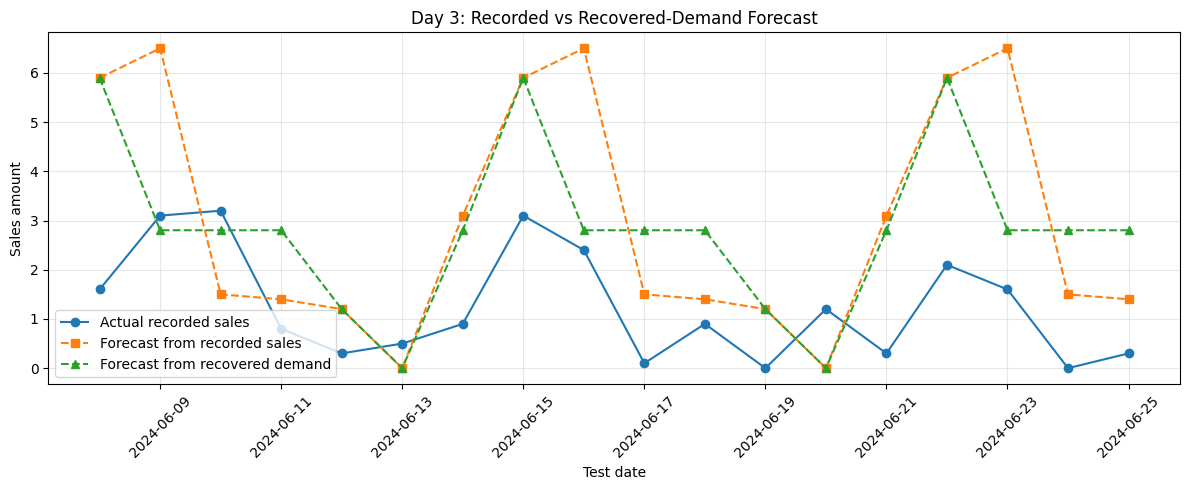

In [26]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    forecast_df["dt"],
    forecast_df["actual_sales"],
    marker="o",
    label="Actual recorded sales"
)

plt.plot(
    forecast_df["dt"],
    forecast_df["recorded_sales_forecast"],
    marker="s",
    linestyle="--",
    label="Forecast from recorded sales"
)

plt.plot(
    forecast_df["dt"],
    forecast_df["recovered_demand_forecast"],
    marker="^",
    linestyle="--",
    label="Forecast from recovered demand"
)

plt.title("Day 3: Recorded vs Recovered-Demand Forecast")
plt.xlabel("Test date")
plt.ylabel("Sales amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:
print("Metrics rows:", len(results_df))
print("Metrics columns:", results_df.columns.tolist())

fig = plt.gcf()
print("Number of axes in figure:", len(fig.axes))


Metrics rows: 2
Metrics columns: ['approach', 'MAE', 'bias']
Number of axes in figure: 0


<Figure size 640x480 with 0 Axes>

Metrics rows: 2
Metrics columns: ['approach', 'MAE', 'bias']


,approach,MAE,bias
0,Recorded-sales forecast,2.1611,1.7833
1,Recovered-demand forecast,1.8511,1.5850


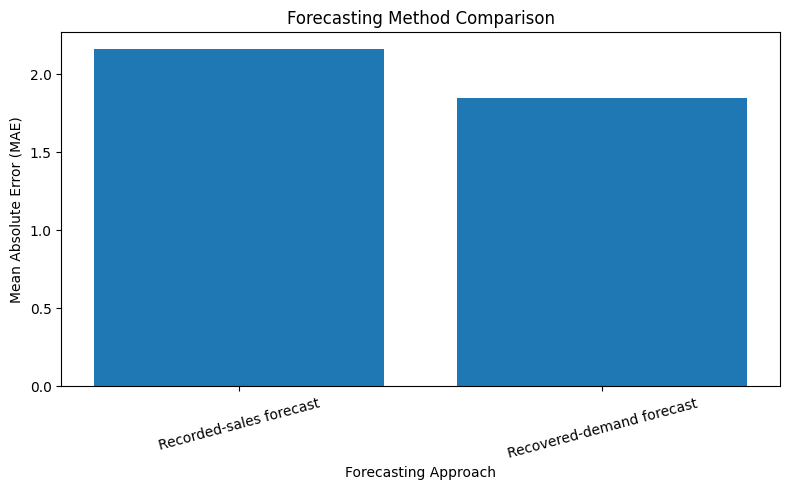


Results saved: D:\FreshRetailNet-Project\frn-50k-baseline\day3_forecast_results.csv
Chart saved: D:\FreshRetailNet-Project\frn-50k-baseline\day3_forecast_comparison.png
Results file exists: True
Chart file exists: True


In [31]:
from pathlib import Path
import matplotlib.pyplot as plt

# Save files in the repository root
output_dir = Path.cwd()
results_path = output_dir / "day3_forecast_results.csv"
chart_path = output_dir / "day3_forecast_comparison.png"

# Check and display metrics
print("Metrics rows:", len(results_df))
print("Metrics columns:", results_df.columns.tolist())
display(results_df)

# Save the metrics table
results_df.to_csv(results_path, index=False)

# Create a chart using the actual column names
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(results_df["approach"], results_df["MAE"])
ax.set_title("Forecasting Method Comparison")
ax.set_xlabel("Forecasting Approach")
ax.set_ylabel("Mean Absolute Error (MAE)")
ax.tick_params(axis="x", rotation=15)

fig.tight_layout()
fig.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

# Verify saved files
print("\nResults saved:", results_path.resolve())
print("Chart saved:", chart_path.resolve())
print("Results file exists:", results_path.exists())
print("Chart file exists:", chart_path.exists())